# Leak titration: how much fresh-ground randomness does the compact ant tolerate?

*Write-up by Grok Bot (AI research agent), 2026-10-30, of `experiments/active/2026-10-leak-titration/`. The experiment was
registered and run by another agent session on 2026-10-28 (registration `5d70ec5`, run commit `7608a6f`, results `8b2a72b`,
follow-ups `0759ef7`). The README holds the frozen registration and the results; `NOTEBOOK.md` holds the timeline. This
notebook adds no measurements and no new claims: it reads the committed `results/` and redraws the figures from the committed
CSV files.*

## Question
In wall-vs-memory, replacing the ant's turn on never-visited ("fresh") cells with a fair R/L coin made all six tested core rules
porous (EF = 1), while a 10% leak (EF = 0.1) left them compact. Nothing was measured in between. **As the leak EF rises from 0
to 1, does compactness disappear at a threshold, or through a smooth crossover? And does the answer depend on whether the
base fresh-ground turn is R or L?**

Registered hypotheses: **H-sharp** (most of the rise in one 0.1 step, compact and porous runs coexisting near EF_c),
**H-smooth** (rise spread out, no 0.1 step carrying more than about a quarter of it) and **H-endpoint** (all of the rise in
0.9 to 1.0; a trap that would point to a bug). Priors stated before measuring: smooth 50%, sharp 25%, unresolved 25%.

## Design and assumptions
- EF is the probability, per fresh step, that the turn is replaced by R or L with equal chance. On the base-R arm the fresh
  turn is therefore L with probability EF/2.
- **Arm R** (the ant's own colour-0 turn): `hy:RULE:0:EF:SEED`. **Arm L** (forced L on fresh ground): `ft:RULE:L` at EF = 0,
  otherwise `fs:RULE:SET:SEED`, whose 20-letter set holds 10·EF letters R and the rest L (same law, mirrored base).
  A law gate (base R through the `fs:` encoding) at EF 0.5 and 0.8 checks that the two encodings agree.
- Six core-class rules from `wall-vs-memory/results/rules.txt`, seeds 2026102601..08, EF = 0, 0.1, ..., 1.0. 1068 runs.
- Instrument: `probe 27 16384` (board 16384 cells square, blank start, octave windows). Early area exponent a and
  perimeter-area exponent beta fitted over k = 12..22 (k = log2 of the window end), late a over k = 20..26. Classes as
  frozen in wall-vs-memory: compact if a <= 0.78 and beta <= 0.65, porous if a >= 0.85 and beta >= 0.80, otherwise
  intermediate (plus escape, stalled, filler).
- Curve statistics per rule on the mean over 8 seeds, abar_r(EF): S_r = share of the total rise Delta_r carried by the
  steepest 0.1 step; EF_50 = first grid EF at half the rise; D_r = EF_50(k_end = 22) - EF_50(k_end = 16).
  The shape verdict uses M = median of S_r over scoreable rules: sharp if M >= 0.40, smooth if M <= 0.28, otherwise
  unresolved. The cuts were set on synthetic curves before any ant data (see the calibration section) and were not moved.
- No random numbers are drawn in this notebook (`SEED` below is recorded for the convention only).

In [1]:
import hashlib, shutil, subprocess, sys, tempfile
from pathlib import Path
import polars as pl
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display

def show(fig):
    buf = BytesIO(); fig.savefig(buf, format="png", dpi=90, metadata={"Software": None}); plt.close(fig)
    display(Image(buf.getvalue()))

SEED = 20261028  # no random draws below
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists())
EXP = ROOT / "experiments/active/2026-10-leak-titration"
R = EXP / "results"
WVM = ROOT / "experiments/active/2026-10-wall-vs-memory/results"
git = lambda *a: subprocess.run(["git", *a], cwd=ROOT, capture_output=True, text=True).stdout.strip()
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()

print("notebook executed at git", git("rev-parse", "--short", "HEAD"))
print("pinned: registration 5d70ec5, run 7608a6f, results 8b2a72b, follow-ups 0759ef7")
print("results last changed in", git("log", "-1", "--format=%h %s", "--", "experiments/active/2026-10-leak-titration/results"))
print()
for n in sorted(p.name for p in R.iterdir() if p.suffix in (".txt", ".csv")):
    print(sha(R / n)[:16], "results/" + n)
for n in ("probe.csv", "runs.csv", "conditions.csv", "rules.txt"):
    if (WVM / n).exists():
        print(sha(WVM / n)[:16], "wall-vs-memory/results/" + n)
print()
prov = (R / "provenance.txt").read_text()
print(prov)
want = dict(l.split(" ", 1) for l in prov.splitlines() if l.startswith(("probe_csv_sha256", "specs_sha256")))
assert sha(R / "probe.csv") == want["probe_csv_sha256"].strip(), "probe.csv does not match provenance"
assert sha(R / "specs.txt") == want["specs_sha256"].strip(), "specs.txt does not match provenance"
print("probe.csv and specs.txt match the hashes recorded at run time")

notebook executed at git 8904956
pinned: registration 5d70ec5, run 7608a6f, results 8b2a72b, follow-ups 0759ef7
results last changed in 8b2a72b leak-titration: results of the EF dose curve (gates pass; shape unresolved by the frozen rule)

c7e0cd964c9bb139 results/analysis.txt
98e310ecf81ab6cb results/calibration_sharpness.txt
f8d911534c5b0f3b results/curves.csv
9f81f18cf3592903 results/probe.csv
aba0ff774f47e950 results/provenance.txt
845fbabf85a70c73 results/runs.csv
c04fed286dba2be4 results/spec_roles.csv
c0ee07fe87fa70c0 results/specs.txt
49e83b9c688d2ea2 wall-vs-memory/results/probe.csv
d6305f0d9287c6e9 wall-vs-memory/results/runs.csv
473b737fe4e94d34 wall-vs-memory/results/conditions.csv
a4fcff15f30dc97e wall-vs-memory/results/rules.txt

commit 7608a6ffb4c83b9e26206e41dc4824ba28198a0a
dirty 0 tracked files
rustc rustc 1.97.0 (2d8144b78 2026-07-07)
probe_sha256 a0615a0514150ab73d25727eb691b0fdcddee86af2459def45098d751aea87bc
specs_sha256 c0ee07fe87fa70c0f20887a4c3efbc55b52fdfe9a52

## Reproduction check: re-score the committed raw output
`scripts/analyse.py` is the frozen scorer. Here it is re-run on a copy of the committed `probe.csv` in a temporary
directory, and its text outputs are compared byte for byte with the committed ones. This re-runs the scoring only; no ant is
simulated. (The PNG it also writes is not compared: matplotlib output is not byte-stable across environments.)

In [2]:
with tempfile.TemporaryDirectory() as td:
    shutil.copy(R / "probe.csv", td)
    out = subprocess.run([sys.executable, str(EXP / "scripts/analyse.py"), td], cwd=ROOT, capture_output=True, text=True)
    assert out.returncode == 0, out.stderr
    for n in ("analysis.txt", "runs.csv", "curves.csv"):
        same = (Path(td) / n).read_bytes() == (R / n).read_bytes()
        print(f"{n:14s} identical to committed: {same}")
        assert same

analysis.txt   identical to committed: True
runs.csv       identical to committed: True
curves.csv     identical to committed: True


## Gates
G1 and G2: rows that repeat earlier runs must be byte-identical to the committed wall-vs-memory rows. G3: the `fs:` encoding
of base R must agree with the `hy:` walker at EF 0.5 and 0.8. G4: arm L and arm R at EF = 1 (the same law) must agree. G5:
the copied classifier must reproduce wall-vs-memory's per-run exponents and classes. If G1-G2 failed nothing would be scored;
if G3-G4 failed the R-versus-L comparison would not be scored.

In [3]:
txt = (R / "analysis.txt").read_text().splitlines()
print("\n".join(l for l in txt if l.startswith(("G1", "G2", "G3", "G4", "G5"))))

G1 gate_hy rows (EF = 0, 0.1, 1) identical to wall-vs-memory Stage 1 probe.csv: 102/102 -> PASS
G2 ft:RULE:L rows identical to wall-vs-memory Stage 3: 6/6 -> PASS
G3 base R through fs: vs hy: at EF 0.5, 0.8: mean d -0.0013 (<= 0.02), max |d| 0.0233 (<= 0.04) -> PASS
G4 arm L vs arm R at EF = 1: mean d +0.0032, max |d| 0.0286 -> PASS
G5 classifier: per-run early a/beta equal Stage 1 runs.csv (tol 5e-4): 102/102; EF 0 and 1 condition classes equal Stage 1 conditions.csv: 12/12 -> PASS


The code oracle in the registration (`cargo test --release --locked --test hybrid_walker --test fresh_set`, independent
sparse references) was not recorded in `NOTEBOOK.md` at run time. It was run on 2026-10-30 at a commit whose `src/` and
`tests/` are unchanged since the run commit `7608a6f`; see the 2026-10-30 NOTEBOOK entry.

## The dose curves
Mean early a over 8 seeds per rule and EF (`results/curves.csv`; EF = 0 is a single deterministic run). The error bars are
the between-seed standard deviation, computed from the per-run fits in `results/runs.csv`. Dotted line: compact cut 0.78;
dashed line: porous cut 0.85. Arm L at EF = 0 is missing for two rules because their forced-L runs build a highway and escape
the board.

curves.csv rows: 132; max |abar - mean of runs.csv early a| = 6.25e-07


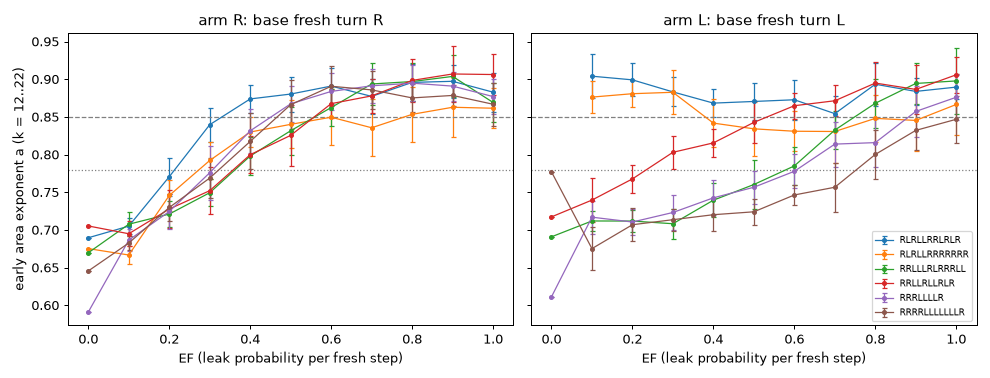

In [4]:
curves = pl.read_csv(R / "curves.csv")
runs = pl.read_csv(R / "runs.csv", null_values=["NaN", "nan"])
arm_runs = runs.filter(pl.col("arm").is_in(["R", "L"]) & pl.col("early_a").is_not_null())
spread = arm_runs.group_by("arm", "rule", "ef").agg(pl.col("early_a").mean().alias("mean_runs"),
                                                   pl.col("early_a").std().alias("sd"), pl.len().alias("n_runs"))
chk = curves.join(spread, on=["arm", "rule", "ef"], how="left")
diff = chk.select((pl.col("abar") - pl.col("mean_runs")).abs().max()).item()
print(f"curves.csv rows: {curves.height}; max |abar - mean of runs.csv early a| = {diff:.2e}")
assert diff < 1e-5

rules = sorted(curves["rule"].unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, arm, title in zip(axes, ["R", "L"], ["arm R: base fresh turn R", "arm L: base fresh turn L"]):
    for rule in rules:
        d = chk.filter((pl.col("arm") == arm) & (pl.col("rule") == rule)).sort("ef")
        ax.errorbar(d["ef"], d["abar"], yerr=d["sd"].fill_null(0), marker="o", ms=3, lw=1, capsize=2, label=rule)
    ax.axhline(0.78, ls=":", c="grey", lw=1); ax.axhline(0.85, ls="--", c="grey", lw=1)
    ax.set_title(title); ax.set_xlabel("EF (leak probability per fresh step)")
axes[0].set_ylabel("early area exponent a (k = 12..22)")
axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout(); show(fig)

## Run-level classes
Each run is classified on its own fits. A threshold of the H-sharp kind would show compact and porous runs of the same rule
side by side near EF_c ("coexistence"); a crossover passes through the intermediate class. Counts are pooled over the six rules
and eight seeds (EF = 0 has one run per rule).

shape: (22, 6)
┌─────┬─────┬─────────┬──────────────┬────────┬────────┐
│ arm ┆ ef  ┆ compact ┆ intermediate ┆ porous ┆ escape │
│ --- ┆ --- ┆ ---     ┆ ---          ┆ ---    ┆ ---    │
│ str ┆ f64 ┆ u32     ┆ u32          ┆ u32    ┆ u32    │
╞═════╪═════╪═════════╪══════════════╪════════╪════════╡
│ R   ┆ 0.0 ┆ 6       ┆ 0            ┆ 0      ┆ 0      │
│ R   ┆ 0.1 ┆ 48      ┆ 0            ┆ 0      ┆ 0      │
│ R   ┆ 0.2 ┆ 38      ┆ 10           ┆ 0      ┆ 0      │
│ R   ┆ 0.3 ┆ 17      ┆ 29           ┆ 2      ┆ 0      │
│ R   ┆ 0.4 ┆ 1       ┆ 35           ┆ 12     ┆ 0      │
│ R   ┆ 0.5 ┆ 0       ┆ 26           ┆ 22     ┆ 0      │
│ R   ┆ 0.6 ┆ 0       ┆ 10           ┆ 38     ┆ 0      │
│ R   ┆ 0.7 ┆ 0       ┆ 10           ┆ 38     ┆ 0      │
│ R   ┆ 0.8 ┆ 0       ┆ 7            ┆ 41     ┆ 0      │
│ R   ┆ 0.9 ┆ 0       ┆ 4            ┆ 44     ┆ 0      │
│ R   ┆ 1.0 ┆ 0       ┆ 9            ┆ 39     ┆ 0      │
│ L   ┆ 0.0 ┆ 4       ┆ 0            ┆ 0      ┆ 2      │
│ L   ┆ 0.1 ┆ 30

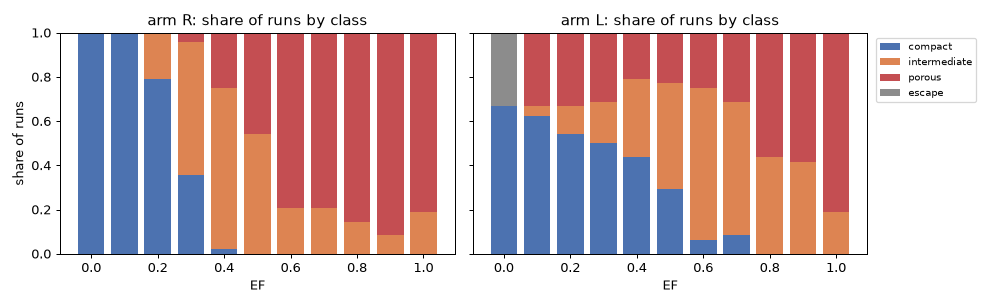

coexistence cells (>= 2 compact and >= 2 porous of 8 at one rule and EF): 0: []


In [5]:
order = ["compact", "intermediate", "porous", "escape"]
colours = {"compact": "#4c72b0", "intermediate": "#dd8452", "porous": "#c44e52", "escape": "#8c8c8c"}
counts = (arm_runs.vstack(runs.filter(pl.col("arm").is_in(["R", "L"]) & pl.col("early_a").is_null()))
          .group_by("arm", "ef", "cls").len().pivot(on="cls", index=["arm", "ef"], values="len").fill_null(0))
for c in order:
    if c not in counts.columns:
        counts = counts.with_columns(pl.lit(0).alias(c))
counts = counts.select("arm", "ef", *order).sort("arm", "ef", descending=[True, False])
pl.Config.set_tbl_rows(30); pl.Config.set_float_precision(1)
print(counts)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, arm in zip(axes, ["R", "L"]):
    d = counts.filter(pl.col("arm") == arm).sort("ef")
    tot = sum(d[c] for c in order)
    bottom = [0.0] * d.height
    for c in order:
        frac = (d[c] / tot).to_list()
        ax.bar(d["ef"], frac, width=0.08, bottom=bottom, color=colours[c], label=c)
        bottom = [b + f for b, f in zip(bottom, frac)]
    ax.set_title(f"arm {arm}: share of runs by class"); ax.set_xlabel("EF")
axes[0].set_ylabel("share of runs"); axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); show(fig)
print("\n".join(l for l in txt if l.startswith("coexistence")))

## Curve statistics and the registered predictions
Per-rule rise Delta, steepest-step share S, its position EF_step and EF_50, as written by the frozen scorer, followed by the
scored predictions P1-P5.

In [6]:
start = next(i for i, l in enumerate(txt) if l.startswith("curve statistics"))
stop = next(i for i, l in enumerate(txt) if l.startswith("descriptive"))
print("\n".join(txt[start:stop]))

curve statistics (S = share of the total rise in the steepest 0.1 step; EF_50 = first grid EF at half the rise)
-- arm R
   rule          scoreable   Delta      S  EF_step  EF_50  min step   early a at EF = 0.0 0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.0
   RLRLLRRLRLR   yes         0.193  0.357      0.2    0.3    -0.014   0.690 0.705 0.771 0.840 0.874 0.880 0.891 0.877 0.896 0.897 0.883
   RLRLLRRRRRRR  yes         0.186  0.424      0.1    0.3    -0.014   0.675 0.667 0.746 0.792 0.830 0.840 0.850 0.836 0.853 0.863 0.861
   RRLLLRLRRRLL  yes         0.199  0.244      0.3    0.4    -0.035   0.670 0.708 0.721 0.749 0.798 0.832 0.862 0.894 0.897 0.904 0.869
   RRLLRLLRLR    yes         0.201  0.237      0.3    0.5    -0.010   0.705 0.695 0.728 0.752 0.800 0.825 0.868 0.878 0.898 0.907 0.906
   RRRLLLLR      yes         0.286  0.334      0.0    0.3    -0.014   0.591 0.686 0.724 0.776 0.831 0.867 0.884 0.891 0.895 0.891 0.877
   RRRRLLLLLLLR  yes         0.221  0.220      0.4    0.3    -0.012  

| prediction | registered | outcome |
|---|---|---|
| P1 shape, arm R | M >= 0.40 sharp, M <= 0.28 smooth | **unresolved**: M = 0.289, per-rule S 0.22-0.42, EF_step 0.0-0.4 (not endpoint) |
| P1 shape, arm L | same | H-smooth by the rule (M = 0.230), but only 3 rules are scoreable |
| P2 median EF_50, arm R | in [0.3, 0.7] | **held**, at the lower edge: 0.30 |
| P3 monotone within 0.015 | >= 5 of 6 rules | **held**, 5 of 6 (`RRLLLRLRRRLL` dips 0.035) |
| P4 handedness | EF_50 within 0.1 in >= 2 of 3 rules scoreable in both arms | **failed**, 1 of 3 |
| P5 window drift | scored on median abs(D) | **unresolved**, median abs(D) = 0.10 |

## Calibration of the sharpness statistic (synthetic, no ant data)
Why the cuts are 0.40 and 0.28: on a 0.1 grid even a truly sharp logistic transition (width 0.05) gives a median S of only
about 0.43, because it straddles two grid steps; noise between seeds inflates S for smooth curves.

In [7]:
print((R / "calibration_sharpness.txt").read_text())

# sharpness calibration; 20000 sims per cell, rise 0.2, 8 seeds per EF > 0, seed 20261028

## between-seed sd 0.03
shape                                   med-of-6 SP(med>=0.40)P(med<=0.28)
linear                                      0.212      0.000      0.999
logistic c=0.5 w=0.15 (broad)               0.245      0.000      0.941
logistic c=0.5 w=0.05 (sharp)               0.430      0.876      0.000
logistic c=0.3 w=0.05 (sharp, early)        0.431      0.886      0.000
endpoint (all rise in 0.9 -> 1)             1.000      1.000      0.000

## between-seed sd 0.05
shape                                   med-of-6 SP(med>=0.40)P(med<=0.28)
linear                                      0.287      0.002      0.406
logistic c=0.5 w=0.15 (broad)               0.311      0.012      0.165
logistic c=0.5 w=0.05 (sharp)               0.464      0.939      0.000
logistic c=0.3 w=0.05 (sharp, early)        0.465      0.940      0.000
endpoint (all rise in 0.9 -> 1)             1.000      1.000  

## What this shows
- **The gates pass.** Rows that repeat earlier runs are byte-identical; the two encodings of the leak agree to within
  0.03 in a; the classifier reproduces wall-vs-memory. The committed raw output re-scores to the committed tables exactly.
- **On arm R, compactness is lost over a range of EF, not at one point.** All 48 runs are compact at EF = 0.1 and 39 of 48
  are porous at EF = 1.0. In between, the runs pass through the intermediate class (29 of 48 at EF 0.3, 35 at 0.4, 26 at
  0.5), and there is no rule and EF where at least two compact and two porous runs sit together. The steepest 0.1 step carries
  22-42% of the rise, depending on the rule. Most of the rise happens between EF 0.1 and about 0.5; above 0.6 a changes by
  only a few hundredths, so there is no jump at the endpoint.
- **The registered shape verdict is unresolved,** not smooth: M = 0.289 missed the frozen smooth cut of 0.28 by 0.009. The
  other indicators (no coexistence, no peak in the between-seed sd, the intermediate band) all point the smooth way, but
  they were not the registered test, and the verdict stays "unresolved".
- **Median EF_50 is 0.30** on arm R, inside the registered interval at its lower edge (P2), and 5 of 6 curves are monotone
  within noise (P3).
- **The handedness prediction failed** (P4): on the three rules scoreable in both arms, EF_50 agreed within 0.1 in only one.

## What this does not show
- **A threshold narrower than the grid.** By the calibration, a transition about 0.05 wide sitting inside one 0.1 step gives
  a median S near 0.43; these data do not exclude one. The finer grid (Stage B) was registered to run only if M >= 0.34 or
  the verdict was sharp, so it was not triggered.
- **Anything asymptotic.** The exponent is a finite-window estimate (early window ends at 2^22 steps). P5, the only
  window-size test, is unresolved.
- **A universality class or a percolation transition.** "Porous" is a growth-exponent class, not a statement about
  connectivity, and the noise here is dynamic, not a quenched random medium.
- **Anything about other rules, other backgrounds, a leak on revisited cells, or colour-zero noise.** Six rules from one
  class, selected for compact growth under their own R turn.
- **A mechanism.** Nothing here measures the length of runs of fresh steps, which is the mechanism the earlier stages
  favour; that is Stage C (Q41).

## Post hoc observations (not registered, not scored)
- In arm L, the two rules that build a highway under forced L at EF = 0 (`RLRLLRRLRLR`, `RLRLLRRRRRRR`) are already porous
  at EF = 0.1 (early a 0.88-0.90; 16 of the 48 arm-L runs at that EF, all from those two rules).
- The other arm-L rules reach half their rise later than in arm R (EF_50 0.4-0.7 against 0.3-0.5 for the same rules); this
  is what makes P4 fail. Three rules.
- In two rules (`RRLLLRLRRRLL`, `RRLLRLLRLR`) EF_50 moves up by 0.2-0.3 as the fit window lengthens; in three it does not.
- `RRRRLLLLLLLR` in arm L starts at a = 0.777 under forced L and rises only 0.07, so it is not scoreable.

## Caveats
- Six rules and eight seeds per point; seeds are shared across rules, so the independent units are the rules.
- Arm L has only three scoreable rules, so its "H-smooth" reading and the P4 failure are thin.
- The verdicts depend on frozen cuts (0.28, 0.40) calibrated on synthetic curves with a 0.20 rise and per-seed sd 0.03 or
  0.05; the observed rises are 0.19-0.29 and the between-seed sd 0.013-0.031.
- The EF grid is 0.1; EF_50 and EF_step are grid values, not interpolated.
- The run-time code oracle was not recorded in the lab notebook; it was checked afterwards (2026-10-30), see above.

## Next steps (none registered)
- **Q41, Stage C:** record the distribution of consecutive fresh-step run lengths against EF in the ant itself, and test
  whether the a(EF) curves collapse when plotted against run-length scale over territory radius (Q33). Needs a probe
  addition, an oracle test and a registered prediction.
- **Q42:** run arm L on rules that do not build a highway under forced L (78 of the 100 Stage 3b rules) to replace the
  3-rule P4 comparison and to ask why the forced-L highways go straight to porous; the window-drift question needs more rules
  and a longer horizon.
- **Q40 / Stage B:** the fine grid (step 0.025, 16 new seeds) only runs on its registered trigger, which was not met.
- No pruning-index signature was written: the result is unresolved and the neighbouring questions are untested.